# Auto MPG — SVM implémentés from scratch
**Objectif :** prédire une classe de consommation (SVC linéaire et RBF), puis le MPG (SVR linéaire).
Un MPG élevé correspond à une consommation faible. Trois algorithmes, deux implémentations.
Les données et les transformations sont communes aux deux notebooks. Les sorties sont conservées.

In [1]:
IMPLEMENTATION = 'from_scratch'

import os
# Évite que les petits QP utilisent des dizaines de threads BLAS.
for key in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[key] = '1'
from pathlib import Path
import sys, json, time
ROOT = Path.cwd().resolve()
if not (ROOT / 'prepare_data.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'prepare_data.py').exists():
    raise RuntimeError('Lancer le notebook depuis la racine ou son dossier.')
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
get_ipython().run_line_magic('matplotlib', 'inline')
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error, r2_score)
from prepare_data import (load_data, make_preprocessor, class_labels, validation_split,
    CLASS_NAMES, EPSILONS, SVC_C, SVR_C)
sns.set_theme(style='whitegrid')
train, test, thresholds = load_data()
OUT = ROOT / IMPLEMENTATION
for directory in ['predictions', 'metrics']:
    (OUT / directory).mkdir(parents=True, exist_ok=True)
classification_rows, regression_rows, validation_rows = [], [], []
svc_predictions, svr_predictions, diagnostics = {}, [], []

## 1. Exploration des données

,car_id,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,367,28.0,4,112.0,88.0,2605,19.6,82,usa,chevrolet cavalier
1,335,35.0,4,122.0,88.0,2500,15.1,80,europe,triumph tr7 coupe
2,317,34.3,4,97.0,78.0,2188,15.8,80,europe,audi 4000
3,158,16.0,8,318.0,150.0,4498,14.5,75,usa,plymouth grand fury
4,137,13.0,8,350.0,150.0,4699,14.5,74,usa,buick century luxus (sw)


,car_id,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
count,313.000000,313.000000,313.000000,313.000000,313.000000,313.000000,313.000000,313.000000,313,313
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,250
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,usa,ford pinto
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,200,5
mean,193.677316,23.007348,5.511182,198.635783,105.533546,3012.629393,15.495847,75.840256,NaN,NaN
std,113.341135,7.552664,1.708023,106.490256,39.280627,855.468673,2.768009,3.640941,NaN,NaN
min,2.000000,9.000000,3.000000,68.000000,46.000000,1649.000000,8.500000,70.000000,NaN,NaN
25%,97.000000,17.000000,4.000000,105.000000,76.000000,2255.000000,13.700000,73.000000,NaN,NaN
50%,191.000000,22.000000,4.000000,151.000000,95.000000,2855.000000,15.500000,76.000000,NaN,NaN
75%,289.000000,28.400000,8.000000,302.000000,129.000000,3664.000000,17.000000,79.000000,NaN,NaN


,train,test
car_id,0,0
mpg,0,0
cylinders,0,0
displacement,0,0
horsepower,0,0
weight,0,0
acceleration,0,0
model_year,0,0
origin,0,0
name,0,0


Dimensions train / test : (313, 10) (79, 10)
Source avant nettoyage : 398 ; après : 392


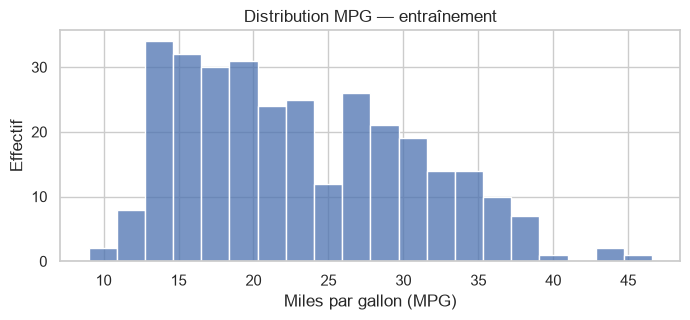

In [2]:
display(train.head())
display(train.describe(include='all'))
display(pd.DataFrame({'train': train.isna().sum(), 'test': test.isna().sum()}))
print('Dimensions train / test :', train.shape, test.shape)
print('Source avant nettoyage :', thresholds['raw_rows'], '; après :', thresholds['complete_rows'])
fig, ax = plt.subplots(figsize=(8, 3))
sns.histplot(train.mpg, bins=20, ax=ax)
ax.set(title='Distribution MPG — entraînement', xlabel='Miles par gallon (MPG)', ylabel='Effectif')
plt.show()

## 2. Prétraitement et protocole sans fuite de données
Les 6 lignes sans `horsepower` sont supprimées : 392 observations complètes sur 398.
L'identifiant `car_id` est l'index de la source avant suppression. `name` est exclu : texte
presque unique, peu généralisable avec ces modèles et susceptible de mémoriser les véhicules.
`origin` est nominal : encodage One-Hot. `cylinders` est traité comme un compte ordonné numérique ;
ce choix impose un effet linéaire pour les modèles linéaires, une limite explicitement assumée.
Les six variables numériques sont standardisées ; les indicatrices d'origine restent binaires.

Le test de 20 % est figé avec `random_state=16`. Les quantiles 1/3 et 2/3 du train fixent
la définition des trois classes ; les bornes appartiennent à la classe inférieure.
La validation est un holdout stratifié de 25 % du train, graine 16. Son scaler et son encodeur
sont ajustés seulement sur le sous-train. Les quantiles définissent la cible commune sur le train
externe, ils ne sont pas recalculés entre modèles. Le test n'intervient dans aucun choix.

Pour isoler la comparaison des solveurs, les paramètres sont fixés **a priori** :
C SVC = 1, gamma = 1/nombre de caractéristiques transformées, C SVR = 10.
On choisit le noyau SVC par F1 macro de validation et epsilon par MAE de validation
parmi [0.1, 0.5, 1, 2, 5]. Il ne s'agit pas d'une recherche exhaustive de C/gamma.
Le modèle final est réajusté sur tout le train. Les cinq epsilons sont évalués sur le test
comme étude de sensibilité préétablie ; le meilleur n'est jamais sélectionné sur le test.

,seuil,MPG
0,q1,18.1
1,q2,26.0


,effectif
classe,
0,105
1,106
2,102


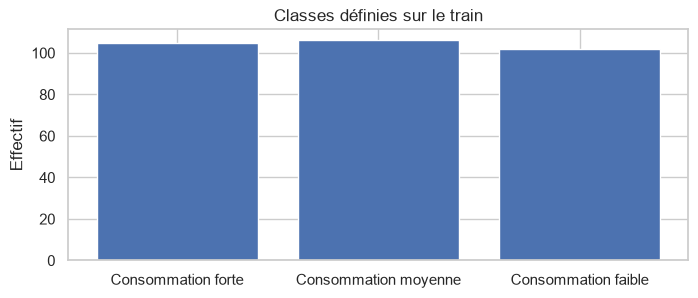

Variables transformées : ['numeric__cylinders' 'numeric__displacement' 'numeric__horsepower'
 'numeric__weight' 'numeric__acceleration' 'numeric__model_year'
 'origin__origin_europe' 'origin__origin_japan' 'origin__origin_usa']
C SVC = 1.0 ; C SVR = 10.0 ; gamma = 0.1111111111111111


In [3]:
y_train_cls = class_labels(train.mpg, thresholds)
y_test_cls = class_labels(test.mpg, thresholds)
subtrain, validation = validation_split(train, thresholds)
validation_preprocessor = make_preprocessor()
X_fit = validation_preprocessor.fit_transform(subtrain)
X_val = validation_preprocessor.transform(validation)
y_fit_cls = class_labels(subtrain.mpg, thresholds)
y_val_cls = class_labels(validation.mpg, thresholds)
# Réajustement pour le modèle final, sur l'ensemble du train exclusivement.
preprocessor = make_preprocessor()
X_train = preprocessor.fit_transform(train)
X_test = preprocessor.transform(test)
GAMMA = 1.0 / X_train.shape[1]
display(pd.DataFrame({'seuil': ['q1', 'q2'], 'MPG': [thresholds['q1'], thresholds['q2']]}))
display(pd.Series(y_train_cls).value_counts().sort_index().rename_axis('classe').to_frame('effectif'))
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(CLASS_NAMES, np.bincount(y_train_cls, minlength=3))
ax.set(title='Classes définies sur le train', ylabel='Effectif')
plt.show()
print('Variables transformées :', preprocessor.get_feature_names_out())
print('C SVC =', SVC_C, '; C SVR =', SVR_C, '; gamma =', GAMMA)

## 3. SVC linéaire : marge souple
Pour une paire de classes, $y_i\in\{-1,+1\}$ et $f(x)=w^Tx+b$.
$$\min_{w,b,\xi\geq0}\frac12\|w\|^2+C\sum_i\xi_i,
\quad y_i(w^Tx_i+b)\geq1-\xi_i.$$
Le dual minimise $\frac12\alpha^TQ\alpha-\sum_i\alpha_i$ sous
$0\leq\alpha_i\leq C$ et $\sum_i\alpha_i y_i=0$, avec $Q_{ij}=y_i y_j K(x_i,x_j)$.
Pour le noyau linéaire, $K(x,z)=x^Tz$ et $w=\sum_i\alpha_i y_i x_i$.
Un grand C pénalise davantage les erreurs de marge. Un support a $\alpha_i>0$.
Le biais utilise les supports libres ($0<\alpha_i<C$), sinon les bornes KKT.
Trois classes nécessitent trois problèmes One-vs-One. Les votes choisissent la classe ;
en cas d'égalité, la première classe ordonnée est retenue, comme libsvm sans `break_ties`.

### Implémentation et optimisation
SLSQP résout le QP dual avec gradient analytique. `ftol=1e-9`, au plus 3000 itérations ; seuil de support 1e-6. Une non-convergence provoque une erreur. Le résidu KKT est mesuré, car le statut du solveur ne suffit pas.

In [4]:
import numpy as np
from itertools import combinations
from scipy.optimize import minimize


def rbf_kernel(X, Z, gamma):
    X, Z = np.asarray(X, float), np.asarray(Z, float)
    distances = np.maximum((X*X).sum(1)[:, None] + (Z*Z).sum(1)[None, :] - 2*X@Z.T, 0)
    return np.exp(-gamma * distances)


class BinarySVC:
    """Dual convexe à marge souple résolu par SLSQP avec gradient analytique."""
    def __init__(self, C=1., kernel='linear', gamma=0.1, tol=1e-9, max_iter=3000):
        self.C, self.kernel, self.gamma = C, kernel, gamma
        self.tol, self.max_iter = tol, max_iter

    def _kernel(self, X, Z):
        return X @ Z.T if self.kernel == 'linear' else rbf_kernel(X, Z, self.gamma)

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        if (X.ndim != 2 or y.shape != (len(X),) or not np.isfinite(X).all()
                or set(np.unique(y)) != {-1., 1.} or self.C <= 0
                or self.kernel not in ('linear', 'rbf') or self.gamma <= 0):
            raise ValueError('Entrées SVC invalides : X fini 2D, y dans {-1,+1}, C/gamma positifs.')
        self.X_, self.y_ = X.copy(), y.copy()
        K = self._kernel(X, X)
        Q = K * np.outer(y, y)
        self.result_ = minimize(lambda a: .5*a@Q@a-a.sum(), np.zeros(len(y)),
            jac=lambda a: Q@a-np.ones(len(y)), method='SLSQP',
            bounds=[(0., self.C)]*len(y),
            constraints={'type': 'eq', 'fun': lambda a: a@y, 'jac': lambda a: y},
            options={'ftol': self.tol, 'maxiter': self.max_iter})
        if not self.result_.success:
            raise RuntimeError(f'SVC : échec optimisation : {self.result_.message}')
        self.alpha_ = self.result_.x
        self.support_ = np.flatnonzero(self.alpha_ > 1e-6)
        self.dual_coef_ = self.alpha_ * y
        free = (self.alpha_ > 1e-6) & (self.alpha_ < self.C-1e-6)
        raw = K @ self.dual_coef_
        if free.any():
            self.intercept_ = float(np.mean(y[free]-raw[free]))
        else:
            # Bornes KKT du biais si aucun multiplicateur n'est libre.
            lower = np.r_[1-raw[(y == 1) & (self.alpha_ < self.C-1e-6)],
                          -1-raw[(y == -1) & (self.alpha_ > 1e-6)]]
            upper = np.r_[1-raw[(y == 1) & (self.alpha_ > 1e-6)],
                          -1-raw[(y == -1) & (self.alpha_ < self.C-1e-6)]]
            self.intercept_ = float((lower.max()+upper.min())/2)
        if self.kernel == 'linear':
            self.coef_ = self.dual_coef_ @ X
        margin = y * (raw+self.intercept_)
        residual = np.where(self.alpha_ <= 1e-6, np.maximum(1-margin, 0),
                    np.where(self.alpha_ >= self.C-1e-6, np.maximum(margin-1, 0), abs(margin-1)))
        self.kkt_violation_ = float(residual.max())
        self.equality_residual_ = float(abs(self.alpha_@y))
        norm_squared = float(self.dual_coef_ @ K @ self.dual_coef_)
        self.primal_objective_ = .5*norm_squared+self.C*np.maximum(1-margin, 0).sum()
        self.dual_objective_ = self.alpha_.sum()-.5*norm_squared
        self.duality_gap_ = self.primal_objective_-self.dual_objective_
        return self

    def decision_function(self, X):
        X = np.asarray(X, float)
        return self._kernel(X, self.X_) @ self.dual_coef_ + self.intercept_

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)


class ScratchSVC:
    """Trois classifieurs binaires One-vs-One ; union des supports d'entraînement."""
    def __init__(self, C=1., kernel='linear', gamma=0.1):
        self.C, self.kernel, self.gamma = C, kernel, gamma

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y)
        if X.ndim != 2 or y.shape != (len(X),) or len(np.unique(y)) < 2:
            raise ValueError('Dimensions ou classes SVC invalides.')
        self.classes_ = np.unique(y)
        self.models_, supports = [], []
        for first, second in combinations(self.classes_, 2):
            idx = np.flatnonzero((y == first) | (y == second))
            binary = np.where(y[idx] == first, -1., 1.)
            model = BinarySVC(self.C, self.kernel, self.gamma).fit(X[idx], binary)
            self.models_.append((first, second, model))
            supports.extend(idx[model.support_])
        self.support_ = np.unique(supports)
        self.n_support_ = np.array([np.sum(y[self.support_] == c) for c in self.classes_])
        return self

    def decision_function(self, X):
        """Une colonne par paire ; signe positif en faveur de la seconde classe."""
        return np.column_stack([m.decision_function(X) for _, _, m in self.models_])

    def predict(self, X):
        scores = self.decision_function(X)
        votes = np.zeros((len(X), len(self.classes_)), int)
        for k, (first, second, _) in enumerate(self.models_):
            votes[:, np.searchsorted(self.classes_, first)] += scores[:, k] <= 0
            votes[:, np.searchsorted(self.classes_, second)] += scores[:, k] > 0
        # Comme libsvm, une égalité de votes choisit la première classe ordonnée.
        return self.classes_[votes.argmax(axis=1)]

In [5]:
def make_svc(kernel):
    return ScratchSVC(C=SVC_C, kernel=kernel, gamma=GAMMA)

In [6]:
def classification_experiment(model_name, factory):
    candidate = factory().fit(X_fit, y_fit_cls)
    pv = candidate.predict(X_val)
    val = dict(model=model_name, validation_accuracy=accuracy_score(y_val_cls, pv),
               validation_f1_macro=f1_score(y_val_cls, pv, average='macro'))
    validation_rows.append(val)
    model = factory().fit(X_train, y_train_cls)
    predicted = model.predict(X_test)
    cm = confusion_matrix(y_test_cls, predicted, labels=[0, 1, 2])
    row = dict(model=model_name, C=SVC_C, split='test',
        accuracy=accuracy_score(y_test_cls, predicted),
        precision_macro=precision_score(y_test_cls, predicted, average='macro', zero_division=0),
        recall_macro=recall_score(y_test_cls, predicted, average='macro', zero_division=0),
        f1_macro=f1_score(y_test_cls, predicted, average='macro'),
        n_support=len(model.support_), confusion_matrix=json.dumps(cm.tolist()), **{k:v for k,v in val.items() if k!='model'})
    output = pd.DataFrame(dict(car_id=test.car_id, mpg_real=test.mpg,
        classe_reelle=y_test_cls, classe_predite=predicted, correct=predicted==y_test_cls,
        C=SVC_C, split='test'))
    if model_name == 'svc_rbf':
        row['gamma'] = GAMMA
        output['gamma'] = GAMMA
    classification_rows.append(row)
    output.to_csv(OUT / 'predictions' / f'{model_name}.csv', index=False)
    svc_predictions[model_name] = output
    display(pd.DataFrame([row])); display(output.head(10))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(xticks_rotation=20, cmap='Blues')
    plt.title(f'{IMPLEMENTATION} — {model_name} — test'); plt.tight_layout(); plt.show()
    if hasattr(model, 'models_'):
        for a, b, binary in model.models_:
            diagnostics.append(dict(model=model_name, pair=f'{a}/{b}',
                iterations=binary.result_.nit, kkt=binary.kkt_violation_,
                equality=binary.equality_residual_, duality_gap=binary.duality_gap_))
    return model


def regression_experiment(epsilon):
    candidate = make_svr(epsilon).fit(X_fit, subtrain.mpg.to_numpy())
    pv = candidate.predict(X_val)
    val_mae = mean_absolute_error(validation.mpg, pv)
    model = make_svr(epsilon).fit(X_train, train.mpg.to_numpy())
    predicted = model.predict(X_test)
    error = predicted-test.mpg.to_numpy()
    row = dict(model='svr_linear', epsilon=epsilon, C=SVR_C, split='test',
        mae=mean_absolute_error(test.mpg, predicted), mse=mean_squared_error(test.mpg, predicted),
        rmse=np.sqrt(mean_squared_error(test.mpg, predicted)), r2=r2_score(test.mpg, predicted),
        n_support=len(model.support_), support_percentage=100*len(model.support_)/len(train),
        validation_mae=val_mae)
    regression_rows.append(row)
    output = pd.DataFrame(dict(car_id=test.car_id, mpg_real=test.mpg,
        mpg_predicted=predicted, signed_error=error, absolute_error=abs(error),
        epsilon=epsilon, C=SVR_C, outside_epsilon_tube=abs(error)>epsilon, split='test'))
    svr_predictions.append(output)
    if hasattr(model, 'duality_gap_'):
        diagnostics.append(dict(model='svr_linear', epsilon=epsilon,
            iterations=model.result_.nit, primal_violation=model.constraint_violation_,
            stationarity=model.stationarity_residual_, equality=model.equality_residual_,
            duality_gap=model.duality_gap_))
    return model

,model,C,split,accuracy,precision_macro,recall_macro,f1_macro,n_support,confusion_matrix,validation_accuracy,validation_f1_macro
0,svc_linear,1.0,test,0.848101,0.867742,0.851891,0.854131,141,"[[18, 3, 0], [0, 21, 3], [0, 6, 28]]",0.759494,0.763814


,car_id,mpg_real,classe_reelle,classe_predite,correct,C,split
0,278,31.5,2,2,True,1.0,test
1,202,17.5,0,1,False,1.0,test
2,85,13.0,0,0,True,1.0,test
3,373,24.0,1,2,False,1.0,test
4,214,13.0,0,0,True,1.0,test
5,107,18.0,0,1,False,1.0,test
6,58,25.0,1,1,True,1.0,test
7,239,30.0,2,2,True,1.0,test
8,314,26.4,2,2,True,1.0,test
9,77,22.0,1,1,True,1.0,test


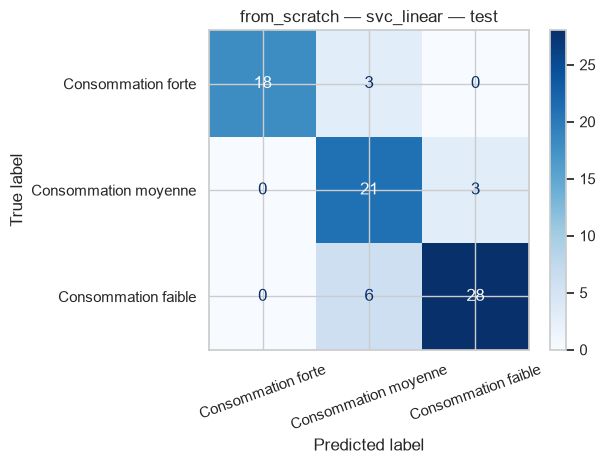

In [7]:
linear_model = classification_experiment('svc_linear', lambda: make_svc('linear'))

## 4. SVC à noyau RBF
$$K(x,z)=\exp(-\gamma\|x-z\|^2).$$
Le dual reste identique, avec cette matrice de Gram. La frontière devient non linéaire.
Gamma règle la portée : une grande valeur rend l'influence d'un point très locale.
Il n'existe pas de vecteur w explicite dans l'espace d'entrée :
$f(x)=\sum_i\alpha_i y_i K(x_i,x)+b$. L'implémentation du noyau et du solveur
est visible dans la cellule précédente pour éviter de dupliquer l'optimisation.

,model,C,split,accuracy,precision_macro,recall_macro,f1_macro,n_support,confusion_matrix,validation_accuracy,validation_f1_macro,gamma
0,svc_rbf,1.0,test,0.835443,0.83723,0.839986,0.837133,172,"[[19, 2, 0], [2, 19, 3], [0, 6, 28]]",0.810127,0.813947,0.111111


,car_id,mpg_real,classe_reelle,classe_predite,correct,C,split,gamma
0,278,31.5,2,2,True,1.0,test,0.111111
1,202,17.5,0,1,False,1.0,test,0.111111
2,85,13.0,0,0,True,1.0,test,0.111111
3,373,24.0,1,2,False,1.0,test,0.111111
4,214,13.0,0,0,True,1.0,test,0.111111
5,107,18.0,0,1,False,1.0,test,0.111111
6,58,25.0,1,1,True,1.0,test,0.111111
7,239,30.0,2,2,True,1.0,test,0.111111
8,314,26.4,2,2,True,1.0,test,0.111111
9,77,22.0,1,1,True,1.0,test,0.111111


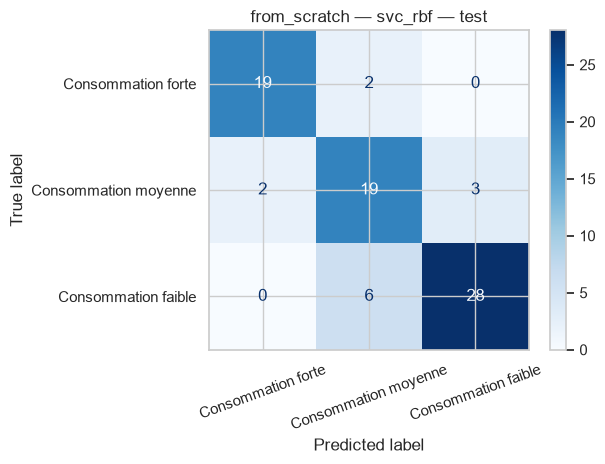

In [8]:
rbf_model = classification_experiment('svc_rbf', lambda: make_svc('rbf'))

## 5. SVR linéaire et perte epsilon-insensible
$$L_\epsilon(y,f)=\max(0,|y-f|-\epsilon).$$
$$\min_{w,b,\xi\geq0}\frac12\|w\|^2+C\sum_i\xi_i,$$
avec $y_i-f_i\leq\epsilon+\xi_i$ et $f_i-y_i\leq\epsilon+\xi_i$.
Un seul slack suffit : au plus une des deux erreurs peut être positive pour epsilon positif.
C équilibre régularisation et erreur ; epsilon fixe la demi-largeur du tube, en MPG.
Le biais n'est pas régularisé. La cible MPG n'est pas standardisée.
Le dual utilise $\beta_i=\alpha_i-\alpha_i^*$, $\sum_i\beta_i=0$,
$0\leq\alpha_i,\alpha_i^*\leq C$ et $w=X^T\beta$.
Un point hors du tube sur le **test** n'est pas un support : les supports appartiennent au train.

### Implémentation SVR
SLSQP résout le QP primal avec contraintes linéaires explicites et gradient analytique. Les multiplicateurs des inégalités donnent alpha et alpha*. Seuil support : 1e-5. Nous contrôlons faisabilité, stationnarité et écart primal-dual. L’optimisation dense est pédagogique, peu adaptée aux très grands jeux de données.

**Stabilité numérique :** tout l’objectif primal est divisé par C avant optimisation. Cette multiplication par une constante positive conserve l’optimum. Les multiplicateurs retournés sont ensuite multipliés par C pour retrouver les coefficients du problème original.

In [9]:
from scipy.optimize import LinearConstraint, Bounds


def epsilon_insensitive_loss(y, prediction, epsilon):
    return np.maximum(np.abs(np.asarray(y)-np.asarray(prediction))-epsilon, 0.)


class ScratchSVR:
    """QP primal epsilon-SVR linéaire ; SciPy optimise, sans estimateur sklearn."""
    def __init__(self, C=10., epsilon=0.1, tol=1e-9, max_iter=3000):
        self.C, self.epsilon, self.tol, self.max_iter = C, epsilon, tol, max_iter

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        if (X.ndim != 2 or y.shape != (len(X),) or not np.isfinite(X).all()
                or not np.isfinite(y).all() or self.C <= 0 or self.epsilon < 0):
            raise ValueError('Entrées SVR invalides : dimensions, valeurs finies, C>0, epsilon>=0.')
        n, p = X.shape
        # z = [w (p), b (1), xi (n)]. Un seul slack par observation suffit.
        A = np.vstack([np.c_[X, np.ones(n), np.eye(n)],
                       np.c_[-X, -np.ones(n), np.eye(n)]])
        lower = np.r_[y-self.epsilon, -y-self.epsilon]
        def objective(z):
            return .5*z[:p]@z[:p]+self.C*z[p+1:].sum()
        def gradient(z):
            return np.r_[z[:p], 0., np.full(n, self.C)]
        start = np.r_[np.zeros(p), np.median(y),
                      epsilon_insensitive_loss(y, np.median(y), self.epsilon)+1e-4]
        # Diviser tout l'objectif par C conserve l'optimum et améliore l'échelle.
        self.result_ = minimize(lambda z: objective(z)/self.C, start,
            jac=lambda z: gradient(z)/self.C, method='SLSQP',
            bounds=Bounds(np.r_[np.full(p+1, -np.inf), np.zeros(n)], np.inf),
            constraints=LinearConstraint(A, lower, np.inf),
            options={'ftol': self.tol, 'maxiter': self.max_iter})
        if not self.result_.success:
            raise RuntimeError(f'SVR : échec optimisation : {self.result_.message}')
        z = self.result_.x
        self.coef_, self.intercept_, self.slack_ = z[:p], float(z[p]), z[p+1:]
        # SciPy >=1.16 fournit les multiplicateurs des 2n inégalités.
        multipliers = self.result_.multipliers*self.C
        self.alpha_, self.alpha_star_ = multipliers[:n], multipliers[n:]
        self.dual_coef_ = self.alpha_-self.alpha_star_
        self.support_ = np.flatnonzero(self.alpha_+self.alpha_star_ > 1e-5)
        self.n_support_ = len(self.support_)
        self.constraint_violation_ = float(max(0., np.max(lower-A@z)))
        self.equality_residual_ = float(abs(self.dual_coef_.sum()))
        self.stationarity_residual_ = float(np.max(abs(self.coef_-X.T@self.dual_coef_)))
        self.primal_objective_ = float(objective(z))
        self.dual_objective_ = float(-.5*np.linalg.norm(X.T@self.dual_coef_)**2
            -self.epsilon*(self.alpha_+self.alpha_star_).sum()+y@self.dual_coef_)
        self.duality_gap_ = self.primal_objective_-self.dual_objective_
        return self

    def predict(self, X):
        return np.asarray(X, float) @ self.coef_ + self.intercept_

In [10]:
def make_svr(epsilon):
    return ScratchSVR(C=SVR_C, epsilon=epsilon)

In [11]:
svr_models = {}
for epsilon in EPSILONS:
    svr_models[epsilon] = regression_experiment(epsilon)
display(pd.DataFrame(regression_rows))

,model,epsilon,C,split,mae,mse,rmse,r2,n_support,support_percentage,validation_mae
0,svr_linear,0.1,10.0,test,2.731546,15.613370,3.951376,0.784471,302,96.485623,2.418785
1,svr_linear,0.5,10.0,test,2.732572,15.936827,3.992096,0.780006,269,85.942492,2.429747
2,svr_linear,1.0,10.0,test,2.729918,15.652146,3.956279,0.783936,228,72.843450,2.480177
3,svr_linear,2.0,10.0,test,2.702506,14.590998,3.819817,0.798584,148,47.284345,2.513575
4,svr_linear,5.0,10.0,test,2.868125,13.762438,3.709776,0.810022,37,11.821086,2.912655


## 6. Étude expérimentale d’epsilon
Le choix est déterminé par la MAE de validation. Les courbes de test servent à décrire les cinq expériences prévues.

Noyau choisi sur validation : svc_rbf
Epsilon choisi sur validation : 0.1


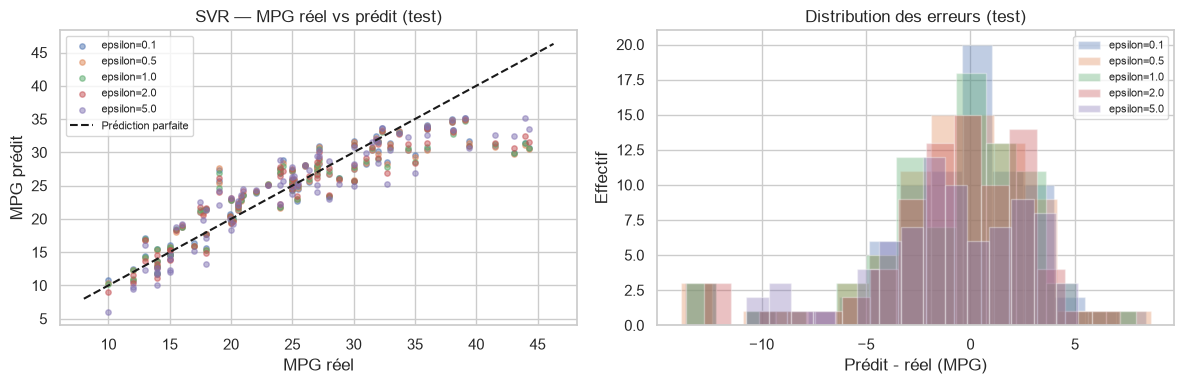

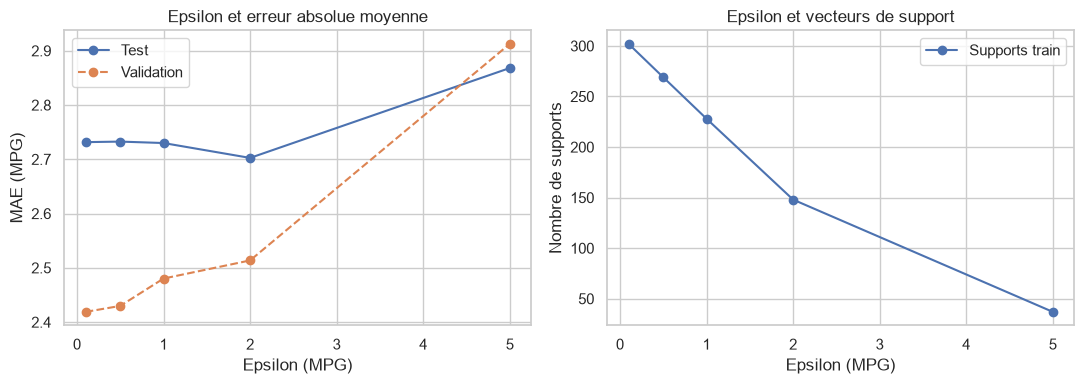

In [12]:
regression_metrics = pd.DataFrame(regression_rows)
classification_metrics = pd.DataFrame(classification_rows).fillna({'gamma': 0.0})
best_epsilon = float(regression_metrics.sort_values(['validation_mae', 'epsilon']).iloc[0].epsilon)
best_svc = classification_metrics.sort_values(['validation_f1_macro', 'model'], ascending=[False, True]).iloc[0]
print('Noyau choisi sur validation :', best_svc.model)
print('Epsilon choisi sur validation :', best_epsilon)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for epsilon, model in svr_models.items():
    predicted = model.predict(X_test)
    axes[0].scatter(test.mpg, predicted, s=15, alpha=.5, label=f'epsilon={epsilon}')
    axes[1].hist(predicted-test.mpg, bins=15, alpha=.35, label=f'epsilon={epsilon}')
limits = [min(test.mpg)-2, max(test.mpg)+2]
axes[0].plot(limits, limits, 'k--', label='Prédiction parfaite')
axes[0].set(title='SVR — MPG réel vs prédit (test)', xlabel='MPG réel', ylabel='MPG prédit')
axes[1].set(title='Distribution des erreurs (test)', xlabel='Prédit - réel (MPG)', ylabel='Effectif')
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(regression_metrics.epsilon, regression_metrics.mae, 'o-', label='Test')
axes[0].plot(regression_metrics.epsilon, regression_metrics.validation_mae, 'o--', label='Validation')
axes[0].set(title='Epsilon et erreur absolue moyenne', xlabel='Epsilon (MPG)', ylabel='MAE (MPG)')
axes[0].legend()
axes[1].plot(regression_metrics.epsilon, regression_metrics.n_support, 'o-', label='Supports train')
axes[1].set(title='Epsilon et vecteurs de support', xlabel='Epsilon (MPG)', ylabel='Nombre de supports')
axes[1].legend()
plt.tight_layout(); plt.show()

## 7. Synthèse et exports

In [13]:
classification_metrics.to_csv(OUT / 'metrics/classification_metrics.csv', index=False)
regression_metrics.to_csv(OUT / 'metrics/regression_metrics.csv', index=False)
pd.concat(svr_predictions, ignore_index=True).to_csv(OUT / 'predictions/svr_linear.csv', index=False)
display(classification_metrics)
display(regression_metrics)
if diagnostics:
    print('Diagnostics numériques des modèles finaux :')
    display(pd.DataFrame(diagnostics).astype(object).fillna('—'))
chosen_reg = regression_metrics.loc[regression_metrics.epsilon == best_epsilon].iloc[0]
print(f"SVC retenu : {best_svc.model} ; F1 validation={best_svc.validation_f1_macro:.4f} ; accuracy test={best_svc.accuracy:.4f}")
print(f"SVR retenu : epsilon={best_epsilon} ; MAE validation={chosen_reg.validation_mae:.4f} ; MAE test={chosen_reg.mae:.4f} ; R² test={chosen_reg.r2:.4f}")

,model,C,split,accuracy,precision_macro,recall_macro,f1_macro,n_support,confusion_matrix,validation_accuracy,validation_f1_macro,gamma
0,svc_linear,1.0,test,0.848101,0.867742,0.851891,0.854131,141,"[[18, 3, 0], [0, 21, 3], [0, 6, 28]]",0.759494,0.763814,0.000000
1,svc_rbf,1.0,test,0.835443,0.837230,0.839986,0.837133,172,"[[19, 2, 0], [2, 19, 3], [0, 6, 28]]",0.810127,0.813947,0.111111


,model,epsilon,C,split,mae,mse,rmse,r2,n_support,support_percentage,validation_mae
0,svr_linear,0.1,10.0,test,2.731546,15.613370,3.951376,0.784471,302,96.485623,2.418785
1,svr_linear,0.5,10.0,test,2.732572,15.936827,3.992096,0.780006,269,85.942492,2.429747
2,svr_linear,1.0,10.0,test,2.729918,15.652146,3.956279,0.783936,228,72.843450,2.480177
3,svr_linear,2.0,10.0,test,2.702506,14.590998,3.819817,0.798584,148,47.284345,2.513575
4,svr_linear,5.0,10.0,test,2.868125,13.762438,3.709776,0.810022,37,11.821086,2.912655


Diagnostics numériques des modèles finaux :


,model,pair,iterations,kkt,equality,duality_gap,epsilon,primal_violation,stationarity
0,svc_linear,0/1,35,0.00001,0.0,0.000012,—,—,—
1,svc_linear,0/2,22,0.000014,0.0,0.000023,—,—,—
2,svc_linear,1/2,35,0.000034,0.0,0.000076,—,—,—
3,svc_rbf,0/1,36,0.000011,0.0,0.000036,—,—,—
4,svc_rbf,0/2,33,0.000013,0.0,0.000029,—,—,—
5,svc_rbf,1/2,46,0.000011,0.0,0.000034,—,—,—
6,svr_linear,—,25,—,0.0,-0.0,0.1,0.0,0.0
7,svr_linear,—,29,—,0.0,-0.0,0.5,0.0,0.0
8,svr_linear,—,31,—,0.0,-0.0,1.0,0.0,0.0
9,svr_linear,—,16,—,0.0,0.0,2.0,0.0,0.0


SVC retenu : svc_rbf ; F1 validation=0.8139 ; accuracy test=0.8354
SVR retenu : epsilon=0.1 ; MAE validation=2.4188 ; MAE test=2.7315 ; R² test=0.7845


## Conclusion et limites
Le choix des modèles repose sur la validation affichée ci-dessus. Les métriques de classification
et de régression répondent à deux questions différentes et ne définissent pas un classement unique.
`compare.py` joint les prédictions par identifiant et configuration pour comparer les solveurs.
L'accuracy dépend des seuils de classe ; les MPG ne sont pas des litres/100 km. Le corpus concerne
des véhicules anciens et reste petit. Un seul holdout donne une estimation sensible à la partition ;
une validation croisée imbriquée et une exploration plus large des paramètres prolongeraient l'étude.
Les QP denses from scratch privilégient la lisibilité au passage à l'échelle. Les supports dont le
multiplicateur est presque nul peuvent dépendre de la tolérance numérique.